# Preparation

In [1]:
#@title Import Libs

import os
import glob
import time
import joblib
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from xgboost import XGBRegressor
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

In [2]:
#@title Import Datasets
#@markdown Memuat hasil split data bersih dari Google Drive pribadi atau folder cadangan bersama.

USE_MY_DRIVE = True #@param {type:"boolean"}
SAVE_MODEL_TO_DRIVE = True #@param {type:"boolean"}
SHARED_FOLDER_URL = 'https://drive.google.com/drive/folders/1oj1cqdfyh1ouXThXJbjgamLA6H5nX8nF'

data_dir = 'processed_data'
drive_base_dir = '/content/drive/MyDrive/DataScience-ProjectUAS'
loaded_from_my_drive = False

if USE_MY_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        drive_path = f'{drive_base_dir}/processed_data'
        if os.path.exists(f'{drive_path}/dataset_1_splits.pkl'):
            data_dir = drive_path
            loaded_from_my_drive = True
            print(f"Loaded from personal Google Drive: {data_dir}")
    except ImportError:
        pass

if not loaded_from_my_drive:
    os.makedirs(data_dir, exist_ok=True)
    if not glob.glob(f'{data_dir}/**/dataset_1_splits.pkl', recursive=True):
        print("Downloading splits from shared Google Drive folder...")
        subprocess.run(
            ['gdown', '--folder', SHARED_FOLDER_URL, '-O', data_dir, '--remaining-ok'],
            check=True
        )
    matched = glob.glob(f'{data_dir}/**/dataset_1_splits.pkl', recursive=True)
    data_dir = os.path.dirname(matched[0])
    print(f"Loaded from shared Drive fallback: {data_dir}")

dataset_1 = joblib.load(f'{data_dir}/dataset_1_splits.pkl')
dataset_2 = joblib.load(f'{data_dir}/dataset_2_splits.pkl')
dataset_3 = joblib.load(f'{data_dir}/dataset_3_splits.pkl')

print("All datasets ready for hyperparameter tuning.")

Mounted at /content/drive
Loaded from personal Google Drive: /content/drive/MyDrive/DataScience-ProjectUAS/processed_data
All datasets ready for hyperparameter tuning.


# Hyperparameter Tuning & Overfitting Control Configuration

In [3]:
#@title Konfigurasi Search Space & Cross-Validation
#@markdown Menentukan parameter tuning berbasis RandomizedSearchCV dengan K-Fold Cross-Validation eksklusif pada Training Set.

N_ITER_SEARCH = 12 #@param {type:"slider", min:6, max:30, step:2}
CV_FOLDS = 3 #@param {type:"slider", min:3, max:5, step:1}
RANDOM_STATE = 42 #@param {type:"integer"}
USE_EARLY_STOPPING = True #@param {type:"boolean"}
EARLY_STOPPING_ROUNDS = 30 #@param {type:"integer"}

device = 'cuda' if torch.cuda.is_available() else 'cpu'

datasets_splits = {
    'Dataset 1': dataset_1,
    'Dataset 2': dataset_2,
    'Dataset 3': dataset_3
}

xgb_initial_params = {
    'n_estimators': 100,
    'learning_rate': 0.1,
    'max_depth': 6,
    'tree_method': 'hist',
    'device': device,
    'random_state': RANDOM_STATE
}

param_distributions = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.03, 0.05, 0.1, 0.15],
    'max_depth': [4, 6, 8, 10],
    'min_child_weight': [1, 3, 5, 10],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'gamma': [0, 0.1, 0.5, 1.0],
    'reg_alpha': [0, 0.1, 1.0],
    'reg_lambda': [1.0, 2.0, 5.0]
}

os.makedirs('models', exist_ok=True)
print(f"Active device     : {device.upper()}")
print(f"Search iterations : {N_ITER_SEARCH} | CV Folds: {CV_FOLDS}")
print("Search space      :", param_distributions)

Active device     : CUDA
Search iterations : 12 | CV Folds: 3
Search space      : {'n_estimators': [100, 200, 300, 500], 'learning_rate': [0.03, 0.05, 0.1, 0.15], 'max_depth': [4, 6, 8, 10], 'min_child_weight': [1, 3, 5, 10], 'subsample': [0.7, 0.8, 0.9, 1.0], 'colsample_bytree': [0.7, 0.8, 0.9, 1.0], 'gamma': [0, 0.1, 0.5, 1.0], 'reg_alpha': [0, 0.1, 1.0], 'reg_lambda': [1.0, 2.0, 5.0]}


# Training: Baseline vs Tuned XGBoost Regressor

In [4]:
#@title Jalankan RandomizedSearchCV pada Ketiga Dataset
#@markdown Pencarian hyperparameter dilakukan menggunakan Cross-Validation pada `X_train` dan `y_train` tanpa menyentuh `Test Set`.

initial_models = {}
tuned_models = {}
best_params_summary = {}
tuning_times = {}

kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

for nama, split in datasets_splits.items():
    print(f"\n--- Memproses {nama} ---")
    X_tr, y_tr = split['X_train'], split['y_train']
    X_va, y_va = split['X_val'], split['y_val']

    base_xgb = XGBRegressor(**xgb_initial_params)
    base_xgb.fit(X_tr, y_tr)
    initial_models[nama] = base_xgb

    start_time = time.time()
    search_estimator = XGBRegressor(
        tree_method='hist',
        device=device,
        random_state=RANDOM_STATE
    )

    random_search = RandomizedSearchCV(
        estimator=search_estimator,
        param_distributions=param_distributions,
        n_iter=N_ITER_SEARCH,
        scoring='neg_root_mean_squared_error',
        cv=kf,
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbose=1
    )
    random_search.fit(X_tr, y_tr)

    best_params = random_search.best_params_
    best_params_summary[nama] = best_params

    final_params = {
        **best_params,
        'tree_method': 'hist',
        'device': device,
        'random_state': RANDOM_STATE
    }

    if USE_EARLY_STOPPING:
        final_params['early_stopping_rounds'] = EARLY_STOPPING_ROUNDS
        final_model = XGBRegressor(**final_params)
        final_model.fit(
            X_tr, y_tr,
            eval_set=[(X_va, y_va)],
            verbose=False
        )
    else:
        final_model = XGBRegressor(**final_params)
        final_model.fit(X_tr, y_tr)

    elapsed = time.time() - start_time
    tuned_models[nama] = final_model
    tuning_times[nama] = round(elapsed, 2)

    print(f"Best CV RMSE ({nama}) : {-random_search.best_score_:.4f}")
    print(f"Best Params  ({nama}) : {best_params}")
    print(f"Waktu Tuning ({nama}) : {elapsed:.2f} detik")


--- Memproses Dataset 1 ---
Fitting 3 folds for each of 12 candidates, totalling 36 fits


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [17:20:40] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Best CV RMSE (Dataset 1) : 12039.2559
Best Params  (Dataset 1) : {'subsample': 0.7, 'reg_lambda': 1.0, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 10, 'learning_rate': 0.15, 'gamma': 1.0, 'colsample_bytree': 0.9}
Waktu Tuning (Dataset 1) : 34.90 detik

--- Memproses Dataset 2 ---
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best CV RMSE (Dataset 2) : 0.5007
Best Params  (Dataset 2) : {'subsample': 1.0, 'reg_lambda': 5.0, 'reg_alpha': 1.0, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.03, 'gamma': 0.1, 'colsample_bytree': 1.0}
Waktu Tuning (Dataset 2) : 129.44 detik

--- Memproses Dataset 3 ---
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best CV RMSE (Dataset 3) : 5.1978
Best Params  (Dataset 3) : {'subsample': 1.0, 'reg_lambda': 5.0, 'reg_alpha': 1.0, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.03, 'gamma': 0.1, 'colsample_bytree': 1.0}
Waktu Tuning (Dataset

# Evaluasi Sebelum vs Sesudah Tuning & Kontrol Overfitting

In [5]:
#@title Perbandingan Skor Validasi Sebelum vs Sesudah Tuning
#@markdown Membandingkan Train RMSE, Validation RMSE, MAE, $R^2$, dan Generalization Gap untuk memastikan penurunan error dan kontrol overfitting.

comparison_rows = []

for nama, split in datasets_splits.items():
    X_tr, y_tr = split['X_train'], split['y_train']
    X_va, y_va = split['X_val'], split['y_val']

    m_init = initial_models[nama]
    pred_tr_init = m_init.predict(X_tr)
    pred_va_init = m_init.predict(X_va)

    init_train_rmse = root_mean_squared_error(y_tr, pred_tr_init)
    init_val_rmse = root_mean_squared_error(y_va, pred_va_init)
    init_val_mae = mean_absolute_error(y_va, pred_va_init)
    init_val_r2 = r2_score(y_va, pred_va_init)

    m_tuned = tuned_models[nama]
    pred_tr_tuned = m_tuned.predict(X_tr)
    pred_va_tuned = m_tuned.predict(X_va)

    tuned_train_rmse = root_mean_squared_error(y_tr, pred_tr_tuned)
    tuned_val_rmse = root_mean_squared_error(y_va, pred_va_tuned)
    tuned_val_mae = mean_absolute_error(y_va, pred_va_tuned)
    tuned_val_r2 = r2_score(y_va, pred_va_tuned)

    rmse_improvement_pct = ((init_val_rmse - tuned_val_rmse) / init_val_rmse) * 100

    comparison_rows.append({
        'Dataset': nama,
        'Before_Train_RMSE': init_train_rmse,
        'Before_Val_RMSE': init_val_rmse,
        'Before_Val_MAE': init_val_mae,
        'Before_Val_R2': init_val_r2,
        'After_Train_RMSE': tuned_train_rmse,
        'After_Val_RMSE': tuned_val_rmse,
        'After_Val_MAE': tuned_val_mae,
        'After_Val_R2': tuned_val_r2,
        'Val_RMSE_Change_%': rmse_improvement_pct,
        'Tuning_Time_Sec': tuning_times[nama]
    })

tuning_comparison_df = pd.DataFrame(comparison_rows)
display(tuning_comparison_df.round(4))

,Dataset,Before_Train_RMSE,Before_Val_RMSE,Before_Val_MAE,Before_Val_R2,After_Train_RMSE,After_Val_RMSE,After_Val_MAE,After_Val_R2,Val_RMSE_Change_%,Tuning_Time_Sec
0,Dataset 1,17242.9707,19492.5781,12199.2451,0.9493,3079.7363,10737.0947,5230.5298,0.9846,44.9170,34.90
1,Dataset 2,0.4984,0.5004,0.3993,0.9128,0.5001,0.5003,0.3992,0.9129,0.0219,129.44
2,Dataset 3,3.6973,5.3472,4.2781,0.9804,4.7099,5.2411,4.2025,0.9811,1.9839,30.93


In [6]:
#@title Ringkasan Best Parameters per Dataset
#@markdown Menampilkan kombinasi hyperparameter optimal yang terpilih untuk masing-masing dataset.

best_params_df = pd.DataFrame(best_params_summary).T
display(best_params_df)

,subsample,reg_lambda,reg_alpha,n_estimators,min_child_weight,max_depth,learning_rate,gamma,colsample_bytree
Dataset 1,0.7,1.0,0.0,500.0,3.0,10.0,0.15,1.0,0.9
Dataset 2,1.0,5.0,1.0,200.0,1.0,4.0,0.03,0.1,1.0
Dataset 3,1.0,5.0,1.0,200.0,1.0,4.0,0.03,0.1,1.0


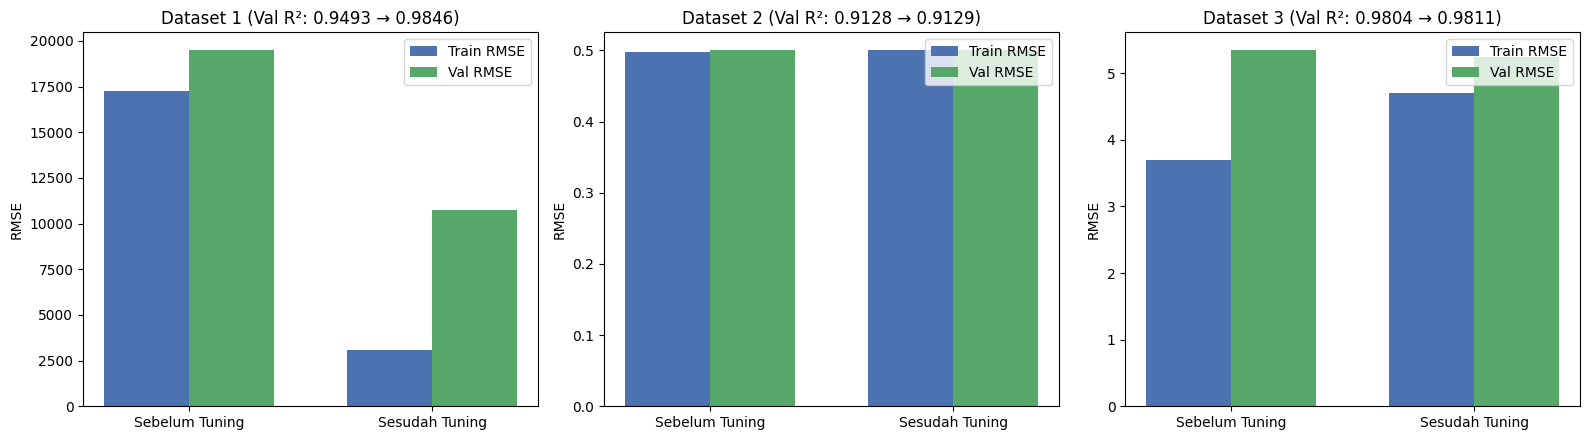

In [7]:
#@title Visualisasi Perbandingan Validation RMSE & Generalization Gap
#@markdown Membandingkan error sebelum dan sesudah tuning serta kesenjangan antara Train RMSE dan Validation RMSE.

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for idx, row in tuning_comparison_df.iterrows():
    ax = axes[idx]
    labels = ['Sebelum Tuning', 'Sesudah Tuning']
    train_vals = [row['Before_Train_RMSE'], row['After_Train_RMSE']]
    val_vals = [row['Before_Val_RMSE'], row['After_Val_RMSE']]

    x = np.arange(len(labels))
    width = 0.35

    ax.bar(x - width/2, train_vals, width, label='Train RMSE', color='#4C72B0')
    ax.bar(x + width/2, val_vals, width, label='Val RMSE', color='#55A868')

    ax.set_title(f"{row['Dataset']} (Val R²: {row['Before_Val_R2']:.4f} → {row['After_Val_R2']:.4f})")
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel('RMSE')
    ax.legend()

plt.tight_layout()
plt.show()

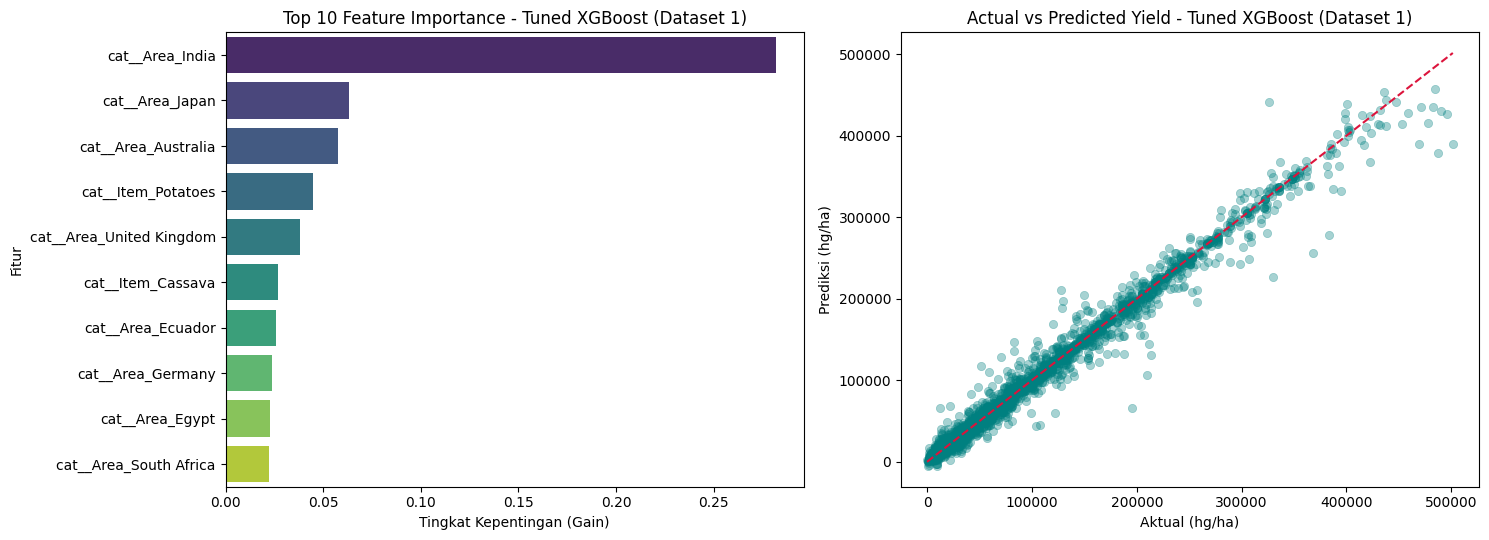

In [8]:
#@title Diagnostik Model Tuned (Dataset 1): Feature Importance & Actual vs Predicted
#@markdown Memeriksa stabilitas fitur dominan dan sebaran prediksi setelah tuning pada Dataset 1.

best_xgb_d1 = tuned_models['Dataset 1']
feat_names = dataset_1['feature_names']

importance_df = pd.DataFrame({
    'Feature': feat_names,
    'Importance': best_xgb_d1.feature_importances_
}).sort_values(by='Importance', ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Top 10 Feature Importance - Tuned XGBoost (Dataset 1)')
axes[0].set_xlabel('Tingkat Kepentingan (Gain)')
axes[0].set_ylabel('Fitur')

y_val_actual = dataset_1['y_val']
y_val_pred = best_xgb_d1.predict(dataset_1['X_val'])

sns.scatterplot(x=y_val_actual, y=y_val_pred, alpha=0.35, color='teal', edgecolor=None, ax=axes[1])
max_val = max(y_val_actual.max(), y_val_pred.max())
axes[1].plot([0, max_val], [0, max_val], color='crimson', linestyle='--', linewidth=1.5)
axes[1].set_title('Actual vs Predicted Yield - Tuned XGBoost (Dataset 1)')
axes[1].set_xlabel('Aktual (hg/ha)')
axes[1].set_ylabel('Prediksi (hg/ha)')

plt.tight_layout()
plt.show()

# Save Tuned Models & Artifacts

In [9]:
#@title Simpan Model Tuned & Hasil Tuning
#@markdown Menyimpan artefak model teroptimasi untuk evaluasi akhir pada Test Set (Bab 7).

for nama, model in tuned_models.items():
    slug = nama.lower().replace(' ', '_')
    model_path = f'models/xgb_tuned_{slug}.pkl'
    joblib.dump(model, model_path)
    print(f"Saved: {model_path}")

artifacts = {
    'best_params': best_params_summary,
    'comparison_df': tuning_comparison_df
}
joblib.dump(artifacts, 'models/xgb_tuning_artifacts.pkl')

if USE_MY_DRIVE and SAVE_MODEL_TO_DRIVE and os.path.exists(drive_base_dir):
    drive_models_dir = f'{drive_base_dir}/models'
    os.makedirs(drive_models_dir, exist_ok=True)
    for fname in os.listdir('models'):
        src = os.path.join('models', fname)
        dst = os.path.join(drive_models_dir, fname)
        joblib.dump(joblib.load(src), dst)
    print(f"All tuned models synced to Google Drive: {drive_models_dir}")

Saved: models/xgb_tuned_dataset_1.pkl
Saved: models/xgb_tuned_dataset_2.pkl
Saved: models/xgb_tuned_dataset_3.pkl
All tuned models synced to Google Drive: /content/drive/MyDrive/DataScience-ProjectUAS/models
